# Restoration benchmark: AdGD vs. quasi-Newton FBS vs. VarPDAL

This notebook runs all three algorithm families in `imrestore.algorithms` on the same denoising task (Shepp-Logan phantom, additive Gaussian noise), each solving the problem structure it is actually designed for:

| Solver | Problem it solves here | Regularizer |
|---|---|---|
| `adaptive_gradient_descent` | unconstrained smooth minimization | Tikhonov (quadratic, smooth) |
| `inertial_quasi_newton_fbs` | `0 in \partial\delta_C(z) + Bz` | Tikhonov + box constraint `[0,1]` |
| `var_pdal` | saddle point `min_x max_y <Dx,y> + g(x) + h(x) - f^*(y)` | total variation (TV) + box constraint |

AdGD cannot handle a box constraint (it is an unconstrained smooth solver) or a non-smooth regularizer like TV (it needs a gradient). Quasi-Newton FBS adds the box constraint via a simple resolvent, but still needs a *smooth* regularizer (Tikhonov) since it has no dual/`K` mechanism for TV. VarPDAL is the only one of the three built for TV, via the saddle-point formulation `K = D` (finite differences), `f^* = ` the dual-ball indicator, exactly because TV has no closed-form proximal operator of its own (see `THEORY.md`).

The point of running all three is not "which wins" in the abstract - it's showing *why* each algorithm exists: as the regularizer and constraints get less friendly (smooth -> smooth+constrained -> non-smooth+constrained), you need a correspondingly more capable solver.

In [1]:
import numpy as np

from imrestore.algorithms.adaptive_gd import adaptive_gradient_descent
from imrestore.algorithms.quasi_newton_fbs import inertial_quasi_newton_fbs
from imrestore.algorithms.var_pdal import var_pdal
from imrestore.metrics.image_quality import psnr, ssim
from imrestore.operators.proximal import prox_box
from imrestore.operators.tv import TotalVariation
from imrestore.utils.io import add_gaussian_noise, load_phantom
from imrestore.utils.visualization import plot_convergence, plot_restoration_grid

## Problem setup

Same noisy phantom used in `scripts/restoration_demo.py`, so results are directly comparable to the VarPDAL-only run there.

In [2]:
x_true = load_phantom("shepp-logan", size=96)
noisy = np.clip(add_gaussian_noise(x_true, sigma=0.12, seed=0), 0.0, 1.0)

print(f"noisy baseline: PSNR {psnr(noisy, x_true):.2f} dB, SSIM {ssim(noisy, x_true):.3f}")

noisy baseline: PSNR 20.19 dB, SSIM 0.320


## 1. `adaptive_gradient_descent` - unconstrained Tikhonov denoising

`min_x  0.5||x - noisy||^2 + (lambda/2)||Dx||^2`, `D` the same finite-difference operator `TotalVariation` uses internally (reused here purely as a linear operator, not for its TV norm). Fully smooth and unconstrained, so plain AdGD applies directly - no box constraint, no proximal step.

In [3]:
tv_op = TotalVariation(weight=1.0)  # weight unused here; only forward/adjoint are
lam = 0.1

def tikhonov_grad(z):
    return (z - noisy) + lam * tv_op.adjoint(tv_op.forward(z))

def tikhonov_obj(z):
    Dz = tv_op.forward(z)
    return 0.5 * np.sum((z - noisy) ** 2) + 0.5 * lam * np.sum(Dz ** 2)

res_adgd = adaptive_gradient_descent(
    tikhonov_grad, noisy.copy(), objective=tikhonov_obj, max_iter=300, tol=1e-10
)
print(f"AdGD: {res_adgd.n_iter} iters, PSNR {psnr(res_adgd.x, x_true):.2f} dB, SSIM {ssim(res_adgd.x, x_true):.3f}")

AdGD: 38 iters, PSNR 21.34 dB, SSIM 0.350


## 2. `inertial_quasi_newton_fbs` - box-constrained Tikhonov denoising

Same Tikhonov objective, now with the pixel-value constraint `x in [0,1]` folded in as `A = ` the normal cone of the box (resolvent = clipping, independent of the metric scale). `B` is the same Tikhonov gradient, which is Lipschitz with constant `L = 1 + 8*lambda` (identity plus the finite-difference Gram operator, whose operator norm is bounded by 8 for this 2-D stencil), so `beta = 1/L`.

In [4]:
L = 1.0 + 8.0 * lam
res_qnfbs = inertial_quasi_newton_fbs(
    B=tikhonov_grad,
    resolvent_A=lambda v, theta: prox_box(v, 0.0, 1.0),
    z0=noisy.copy(),
    beta=1.0 / L,
    objective=tikhonov_obj,
    max_iter=300,
    tol=1e-10,
)
print(f"QN-FBS: {res_qnfbs.n_iter} iters, PSNR {psnr(res_qnfbs.x, x_true):.2f} dB, SSIM {ssim(res_qnfbs.x, x_true):.3f}")

QN-FBS: 30 iters, PSNR 21.34 dB, SSIM 0.350


Note this typically lands very close to the unconstrained AdGD result: at this noise level the unconstrained Tikhonov optimum already stays inside `[0,1]`, so the box constraint doesn't bind and both converge to essentially the same point - a useful sanity check that the constrained solver reduces to the right answer when the constraint is inactive.

## 3. `var_pdal` - box-constrained TV denoising

`min_x max_y <Dx,y> + g(x) + h(x) - f^*(y)`, `g` the box indicator, `h(x) = 0.5||x-noisy||^2`, `f^*` TV's dual-ball indicator. TV has no closed-form prox, which is exactly why this needs the saddle-point/quasi-Newton machinery rather than a direct forward-backward step.

In [5]:
tv = TotalVariation(weight=0.08)
h = lambda x: 0.5 * np.sum((x - noisy) ** 2)
grad_h = lambda x: x - noisy

res_varpdal = var_pdal(
    K=tv.forward,
    K_adjoint=tv.adjoint,
    prox_g=lambda v, tau: prox_box(v, 0.0, 1.0),
    prox_f_conj=tv.prox_conj,
    h=h,
    grad_h=grad_h,
    x1=noisy.copy(),
    y0=np.zeros((2, *x_true.shape)),
    L_h=1.0,
    sigma0=0.1,
    beta=1.0,
    objective=lambda x: h(x) + tv(x),
    max_iter=200,
    tol=1e-9,
)
print(f"VarPDAL: PSNR {psnr(res_varpdal.x, x_true):.2f} dB, SSIM {ssim(res_varpdal.x, x_true):.3f}")

VarPDAL: PSNR 24.40 dB, SSIM 0.562


## Comparison

`lambda` for the Tikhonov baselines was swept beforehand (see `THEORY.md` / commit history) to its near-best achievable PSNR (~0.1), so this isn't a straw-man comparison - TV still wins clearly, which is the well-known qualitative behavior for piecewise-constant images like this phantom: quadratic (Tikhonov) regularization smooths edges along with noise, while TV preserves them.

In [6]:
print(f"{'method':<28}{'PSNR (dB)':>12}{'SSIM':>10}")
for label, res in [
    ("noisy (no restoration)", None),
    ("AdGD (Tikhonov)", res_adgd),
    ("QN-FBS (Tikhonov+box)", res_qnfbs),
    ("VarPDAL (TV+box)", res_varpdal),
]:
    img = noisy if res is None else res.x
    print(f"{label:<28}{psnr(img, x_true):>12.2f}{ssim(img, x_true):>10.3f}")

method                         PSNR (dB)      SSIM
noisy (no restoration)             20.19     0.320
AdGD (Tikhonov)                    21.34     0.350
QN-FBS (Tikhonov+box)              21.34     0.350
VarPDAL (TV+box)                   24.40     0.562


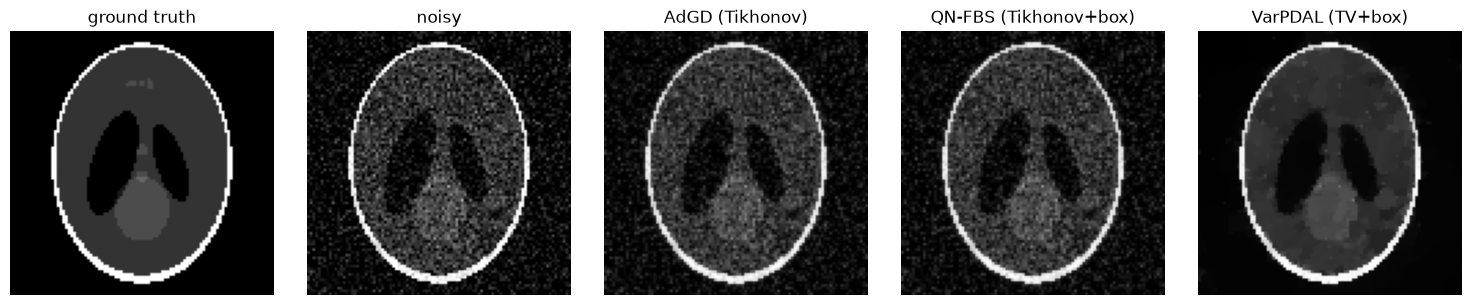

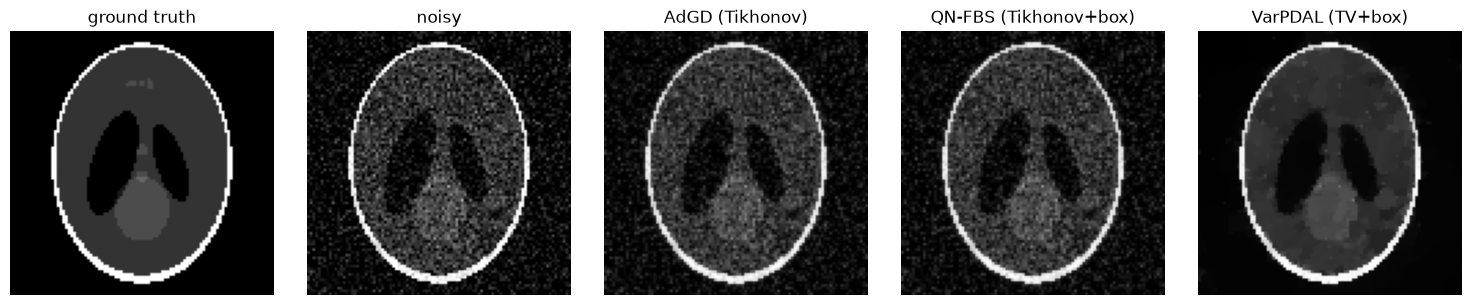

In [7]:
plot_restoration_grid({
    "ground truth": x_true,
    "noisy": noisy,
    "AdGD (Tikhonov)": res_adgd.x,
    "QN-FBS (Tikhonov+box)": res_qnfbs.x,
    "VarPDAL (TV+box)": res_varpdal.x,
})

<Axes: xlabel='iteration', ylabel='objective'>

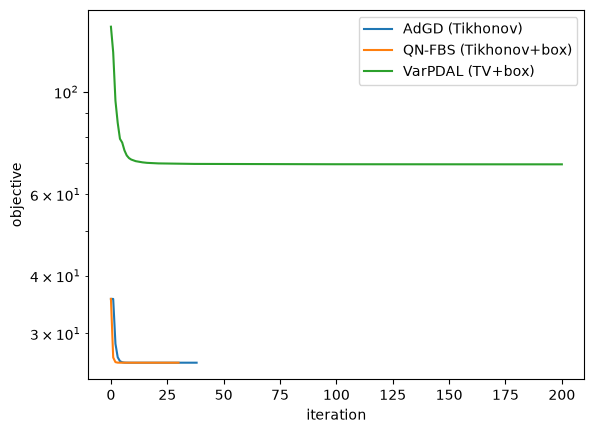

In [8]:
# Objective values aren't directly comparable across different regularizers
# (Tikhonov vs. TV objectives live on different scales); each curve is still
# informative on its own as a convergence check.
plot_convergence({
    "AdGD (Tikhonov)": res_adgd.objective_history,
    "QN-FBS (Tikhonov+box)": res_qnfbs.objective_history,
    "VarPDAL (TV+box)": res_varpdal.objective_history,
})